# Crop Doctor: the model, from data to evaluation

**Task.** A farmer photographs one tomato or potato leaf. The model says which disease it is, or that the leaf is healthy, or that it is "something else" it was not taught.

**Model.** ConvNeXt-Tiny (pretrained on ImageNet-22k), fine-tuned on lab photos and real field photos. **12 classes**: 3 potato, 8 tomato, and one tomato "something else" class.

**What makes it more than a classifier.** The model is checked for *honesty*:
1. **Temperature scaling** makes its confidence match how often it is right.
2. **Conformal prediction** turns the scores into a shortlist that contains the right disease 90% of the time, guaranteed.
3. The app uses the shortlist size: **one disease → answer, 2–3 → ask one question, more → send to an expert.**

**Contents**
1. Dataset: loading and exploring
2. Preprocessing and augmentation
3. Model architecture
4. Training
5. Evaluation on held-out test photos (accuracy, F1, confusion matrix, Grad-CAM)
6. Calibration (is the confidence honest?)
7. Conformal prediction (the 90% guarantee)
8. Selective prediction (answer only when sure)
9. Unknown diseases ("something else")
10. Summary and limitations

All numbers below are computed live in this notebook from the saved model and the split files.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path

# Find the project root (the folder that contains crop_doctor/), wherever the notebook is opened from.
ROOT = Path.cwd().resolve()
while not (ROOT / "crop_doctor").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
# Datasets and trained checkpoints are large and git-ignored. Defaults: <project>/datasets and crop_doctor/outputs.
os.environ.setdefault("CROP_DOCTOR_DATASETS", str(ROOT / "datasets"))
OUTPUTS = Path(os.environ.get("CROP_DOCTOR_OUTPUTS", ROOT / "crop_doctor" / "outputs"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import timm
from PIL import Image
from sklearn.metrics import f1_score, classification_report, confusion_matrix

from crop_doctor import config
from crop_doctor.model.common import IMG_SIZE, MEAN, STD, FrameDataset, build_model, eval_transform
from crop_doctor.model.train_final import strong_train_transform, logits_of
from crop_doctor.model.crops import crops_from_labels, mask_logits, crop_of
from crop_doctor.uncertainty.calibration import softmax, fit_temperature, ece, nll, reliability_bins
from crop_doctor.uncertainty.conformal import (group_quantiles, group_prediction_sets, uniform_noise,
                                               evaluate_sets, class_coverage)
from crop_doctor.uncertainty.selective import risk_coverage, aurc, oracle_aurc

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
torch.manual_seed(config.SEED); np.random.seed(config.SEED)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WORKERS = 4

SPLITS = ROOT / "crop_doctor" / "data" / "splits_v3"
CLASSES = json.loads((SPLITS / "classes.json").read_text())
print("datasets:", config.DATASETS_DIR, "| exists:", config.DATASETS_DIR.exists())
print("device:", DEV, torch.cuda.get_device_name(0) if DEV.type == "cuda" else "")
print("torch", torch.__version__, "| timm", timm.__version__)
print(len(CLASSES), "classes:", CLASSES)

C:\Users\krish\Desktop\ML project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


datasets: C:\Users\krish\Desktop\ML project\datasets | exists: True
device: cuda NVIDIA GeForce RTX 3050 6GB Laptop GPU
torch 2.11.0+cu128 | timm 1.0.31
12 classes: ['potato_early_blight', 'potato_healthy', 'potato_late_blight', 'tomato_bacterial_spot', 'tomato_early_blight', 'tomato_healthy', 'tomato_late_blight', 'tomato_leaf_mold', 'tomato_mosaic_virus', 'tomato_septoria', 'tomato_yellow_curl_virus', 'tomato_something_else']


## 1. Dataset

Four public sources. A split is a small CSV file (path, label, source): **the CSVs are the dataset definition**, so every result can be reproduced.

| Source | What it is | Used for |
|---|---|---|
| **PlantVillage** | Lab photos: one leaf on a plain background | lab train / val / test |
| **PlantDoc** | Real web photos: fields, hands, many leaves | field train / val / cal / **test** |
| **Tanzania potato** | Real farm photos of potato leaves | field train / val / cal / **test** |
| **Tomato-Village** | Indian tomato leaves (on paper) | field train, plus "something else" diseases |

Exact duplicate images (same MD5) were removed so that no photo is in two splits.

The **test photos (`field_test`) were never used for training, choosing the model, or fitting the calibration.**

In [2]:
names = ["lab_train", "lab_val", "lab_test", "field_train", "field_val", "field_cal", "field_test",
         "other_train", "other_val", "unknown_heldout"]
S = {n: pd.read_csv(SPLITS / f"{n}.csv") for n in names}
table = pd.DataFrame({n: S[n]["source"].value_counts() for n in names}).T.fillna(0).astype(int)
table["total"] = table.sum(1)
role = {"lab_train": "train", "lab_val": "-", "lab_test": "test (lab)", "field_train": "train",
        "field_val": "choose best epoch", "field_cal": "calibration", "field_test": "TEST (field)",
        "other_train": "train ('something else')", "other_val": "choose best epoch",
        "unknown_heldout": "never-seen diseases"}
table["role"] = pd.Series(role)
table

source,plantdoc,plantvillage,tanzania,tomato_village,total,role
lab_train,0,13773,0,0,13773,train
lab_val,0,1722,0,0,1722,-
lab_test,0,1723,0,0,1723,test (lab)
field_train,285,0,3600,1450,5335,train
field_val,95,0,450,0,545,choose best epoch
field_cal,95,0,450,0,545,calibration
field_test,476,0,830,0,1306,TEST (field)
other_train,0,0,0,1664,1664,train ('something else')
other_val,0,0,0,295,295,choose best epoch
unknown_heldout,0,0,0,948,948,never-seen diseases


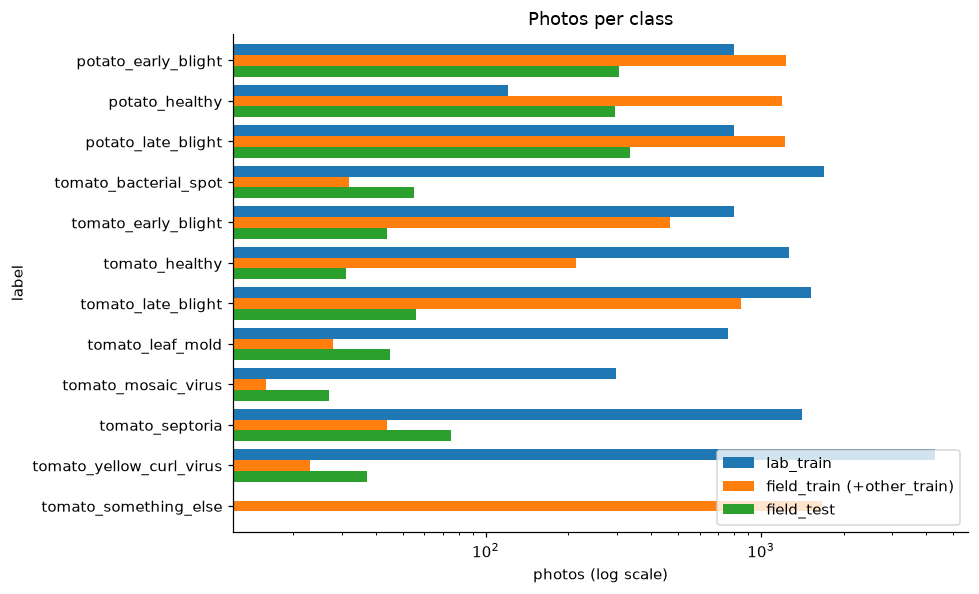

,lab_train,field_train (+other_train),field_test
label,,,
potato_early_blight,800,1233,305
potato_healthy,121,1200,296
potato_late_blight,800,1230,335
tomato_bacterial_spot,1701,32,55
tomato_early_blight,800,468,44
tomato_healthy,1268,213,31
tomato_late_blight,1521,848,56
tomato_leaf_mold,762,28,45
tomato_mosaic_virus,298,16,27


In [3]:
# Class balance: lab photos are plentiful, real field photos are few and very uneven.
counts = pd.DataFrame({
    "lab_train": S["lab_train"]["label"].value_counts(),
    "field_train (+other_train)": pd.concat([S["field_train"], S["other_train"]])["label"].value_counts(),
    "field_test": S["field_test"]["label"].value_counts(),
}).reindex(CLASSES).fillna(0).astype(int)
ax = counts.plot.barh(figsize=(9, 5.5), width=0.8)
ax.set_xscale("log"); ax.set_xlabel("photos (log scale)"); ax.invert_yaxis()
ax.set_title("Photos per class")
plt.tight_layout(); plt.show()
counts

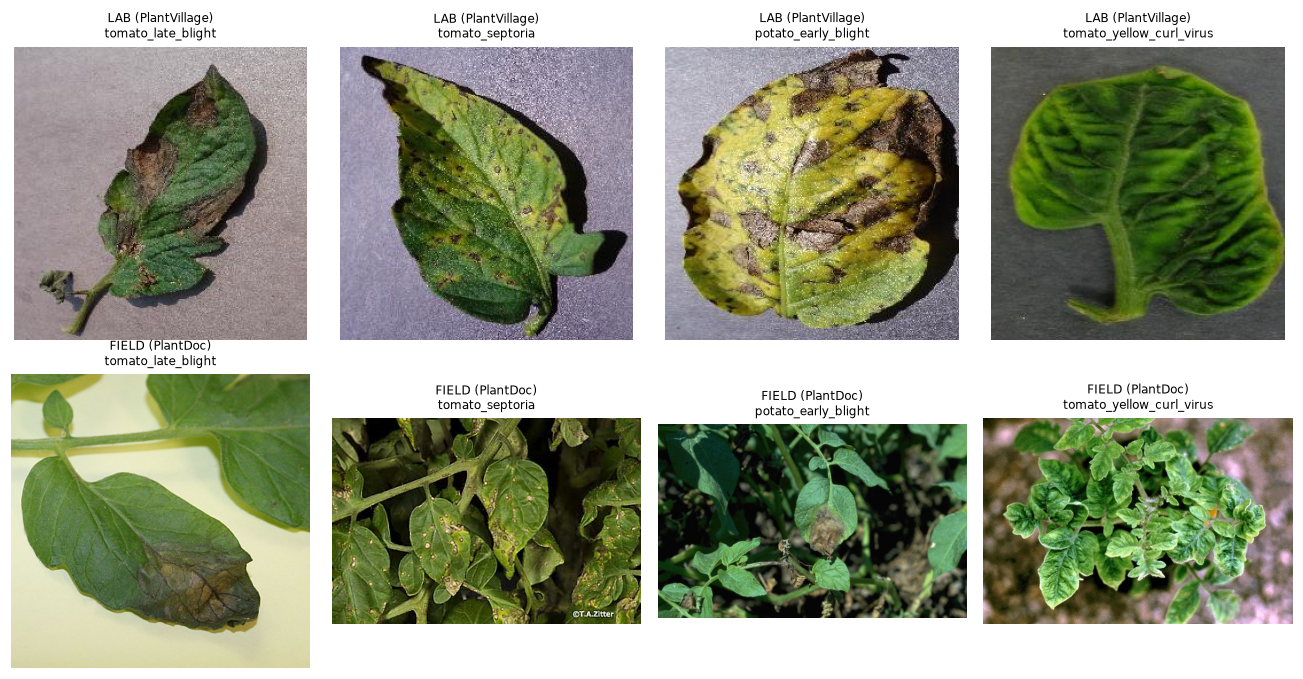

In [4]:
# Lab vs field: the same disease looks very different. This "distribution shift" is the core difficulty.
show = ["tomato_late_blight", "tomato_septoria", "potato_early_blight", "tomato_yellow_curl_virus"]
fig, axes = plt.subplots(2, len(show), figsize=(12, 6.2))
for j, c in enumerate(show):
    for i, (split, src, title) in enumerate([("lab_train", "plantvillage", "LAB (PlantVillage)"),
                                             ("field_test", "plantdoc", "FIELD (PlantDoc)")]):
        df = S[split]; row = df[(df["label"] == c) & (df["source"] == src)].sample(1, random_state=3).iloc[0]
        with Image.open(config.DATASETS_DIR / row["path"]) as im:
            axes[i, j].imshow(im.convert("RGB"))
        axes[i, j].set_title(f"{title}\n{c}", fontsize=8); axes[i, j].axis("off")
plt.tight_layout(); plt.show()

## 2. Preprocessing and augmentation

* **Evaluation:** resize the short side to 256, centre crop 224×224, normalise with ImageNet mean/std. The app does exactly the same.
* **Training:** strong augmentation that imitates hand-held phone photos: tight random crops (30–100% of the image), flips, rotation ±25°, lighting changes and occasional blur.

eval: Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
) 

train: Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.3, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-25.0, 25.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.65, 1.35), contrast=(0.65, 1.35), saturation=(0.65, 1.35), hue=(-0.05, 0.05))
    RandomApply(
    p=0.25
    GaussianBlur(kernel_size=(5, 5), sigma=(0.1, 2.0))
)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)


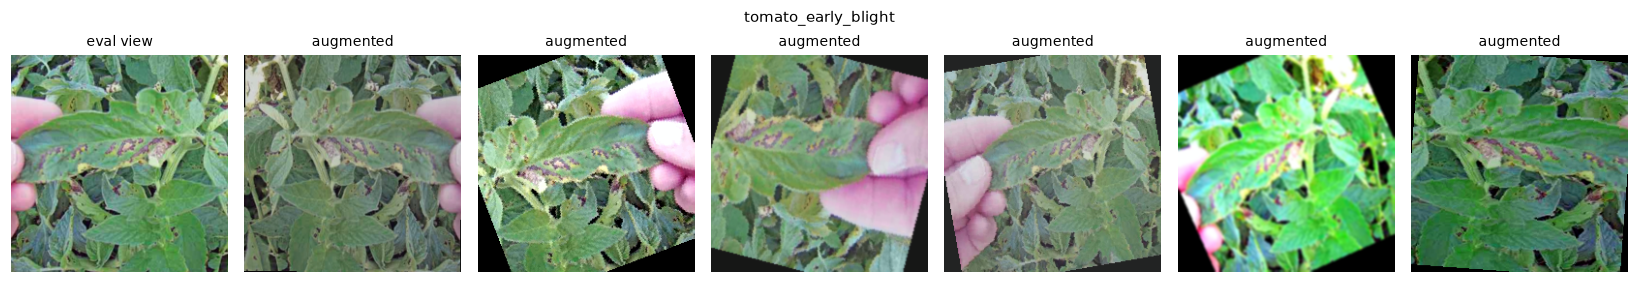

In [5]:
print("eval:", eval_transform(), "\n\ntrain:", strong_train_transform())

def to_img(t):            # undo the normalisation, for display
    return (t.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)).clip(0, 1)

row = S["field_train"][S["field_train"]["source"] == "plantdoc"].sample(1, random_state=1).iloc[0]
with Image.open(config.DATASETS_DIR / row["path"]) as im:
    img = im.convert("RGB")
tf = strong_train_transform(); torch.manual_seed(0)
fig, axes = plt.subplots(1, 7, figsize=(15, 2.6))
axes[0].imshow(to_img(eval_transform()(img))); axes[0].set_title("eval view", fontsize=9)
for a in axes[1:]:
    a.imshow(to_img(tf(img))); a.set_title("augmented", fontsize=9)
for a in axes: a.axis("off")
plt.suptitle(row["label"], fontsize=10); plt.tight_layout(); plt.show()

## 3. Model: ConvNeXt-Tiny

* A modern convolutional network (Liu et al., 2022) built with ideas from vision transformers: large 7×7 kernels, LayerNorm and an inverted bottleneck.
* **Transfer learning:** the weights were pretrained on **ImageNet-22k**, about 14 million images, then fine-tuned on ImageNet-1k (`convnext_tiny.fb_in22k_ft_in1k` in `timm`). Only the last layer is replaced with a new 12-class head.
* **Why this backbone:** on our field validation photos it beat EfficientNet-B0, 61.1% vs 53.7% (Day 5a). Models pretrained on more varied data handle the lab → field shift better.
* **Crop masking:** the farmer tells the app the crop, so the scores of the other crop's diseases are set to −∞ before softmax. A potato leaf can never be called a tomato disease.

In [6]:
ARCH = "convnext_tiny.fb_in22k_ft_in1k"
model = build_model(len(CLASSES), pretrained=False, arch=ARCH)
n_params = sum(p.numel() for p in model.parameters())
print(f"{ARCH}: {n_params/1e6:.1f} M parameters")
print("stages:", [type(s).__name__ for s in model.stages], "| output head:", model.head.fc)
with torch.no_grad():
    print("input (1, 3, 224, 224) -> output", tuple(model(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE)).shape))

convnext_tiny.fb_in22k_ft_in1k: 27.8 M parameters
stages: ['ConvNeXtStage', 'ConvNeXtStage', 'ConvNeXtStage', 'ConvNeXtStage'] | output head: Linear(in_features=768, out_features=12, bias=True)
input (1, 3, 224, 224) -> output (1, 12)


## 4. Training

The recipe (`crop_doctor/model/train_v2.py`):

* **Mixed batches:** every batch is about 40% lab photos and 60% field photos, so the model learns from both worlds.
* **Square-root class balancing:** a class with 4× fewer photos is drawn 2× more often per photo. Full 1/n balancing would repeat a 16-photo class hundreds of times and overfit.
* **Optimiser:** AdamW (lr 1e-4, weight decay 0.05) with a one-cycle learning-rate schedule (10% warm-up). Mixed precision on the GPU, batch size 32.
* **Length:** 10 epochs × 16,000 sampled photos.
* **Model selection:** the best epoch is chosen by **macro-F1 on `field_val`**, so every class counts equally. It is never chosen on the test set.

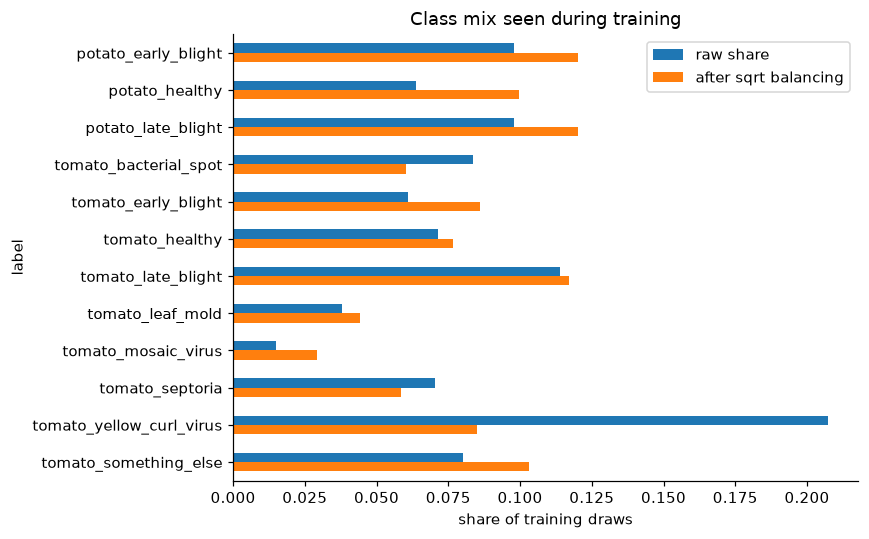

In [7]:
from torch.utils.data import ConcatDataset, DataLoader, WeightedRandomSampler

LAB_SHARE = 0.4
def sqrt_balanced(labels, total_weight):
    counts = labels.map(labels.value_counts())
    w = 1.0 / np.sqrt(counts.to_numpy(dtype=float))
    return w / w.sum() * total_weight

lab, field = S["lab_train"], pd.concat([S["field_train"], S["other_train"]], ignore_index=True)
weights = np.concatenate([sqrt_balanced(lab["label"], LAB_SHARE), sqrt_balanced(field["label"], 1 - LAB_SHARE)])

# What share of training draws each class gets, before vs after balancing
labels_all = pd.concat([lab["label"], field["label"]], ignore_index=True)
raw = labels_all.value_counts(normalize=True).reindex(CLASSES)
balanced = pd.Series(weights).groupby(labels_all).sum().reindex(CLASSES)
pd.DataFrame({"raw share": raw, "after sqrt balancing": balanced}).plot.barh(figsize=(8, 5)).invert_yaxis()
plt.xlabel("share of training draws"); plt.title("Class mix seen during training"); plt.tight_layout(); plt.show()

In [8]:
def train(epochs, samples_per_epoch, lr=1e-4, batch_size=32, save_to=None):
    torch.manual_seed(config.SEED)
    tf = strong_train_transform()
    train_ds = ConcatDataset([FrameDataset(lab, tf), FrameDataset(field, tf)])
    sampler = WeightedRandomSampler(torch.as_tensor(weights), num_samples=samples_per_epoch, replacement=True,
                                    generator=torch.Generator().manual_seed(config.SEED))
    kw = dict(num_workers=WORKERS, pin_memory=DEV.type == "cuda", persistent_workers=True)
    train_dl = DataLoader(train_ds, batch_size=batch_size, sampler=sampler, drop_last=True, **kw)
    val = pd.concat([S["field_val"], S["other_val"]], ignore_index=True)
    val_dl = DataLoader(FrameDataset(val, eval_transform()), batch_size=64, **kw)
    val_y = val["label_idx"].to_numpy()

    net = build_model(len(CLASSES), pretrained=True, arch=ARCH).to(DEV)     # ImageNet-22k weights
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(train_dl), pct_start=0.1)
    scaler = torch.amp.GradScaler(enabled=DEV.type == "cuda")
    loss_fn = torch.nn.CrossEntropyLoss()
    best, history = -1.0, []
    for epoch in range(1, epochs + 1):
        net.train(); t0, total, seen = time.time(), 0.0, 0
        for x, y in train_dl:
            x, y = x.to(DEV, non_blocking=True), y.to(DEV, non_blocking=True)
            with torch.autocast(device_type=DEV.type, enabled=DEV.type == "cuda"):
                loss = loss_fn(net(x), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            total += loss.item() * len(y); seen += len(y)
        pred = mask_logits(logits_of(net, val_dl, DEV), CLASSES, crops_from_labels(val_y, CLASSES)).argmax(1)
        f1 = f1_score(val_y, pred, average="macro")
        history.append({"epoch": epoch, "train_loss": total / seen, "val_macro_f1": f1,
                        "val_acc": (pred == val_y).mean(), "seconds": time.time() - t0})
        print({k: round(float(v), 4) for k, v in history[-1].items()})
        if f1 > best and save_to:
            best = f1
            torch.save({"state_dict": net.state_dict(), "classes": CLASSES, "arch": ARCH, "epoch": epoch}, save_to)
    return pd.DataFrame(history)

In [9]:
# TRAIN_MODE:
#   "demo" - one short epoch (3,200 photos, ~1-2 min on an RTX 3050) to show the loop working
#   "full" - the real recipe: 10 x 16,000 photos (~20 min on an RTX 3050); reproduces the shipped model
#   "skip" - don't train; use the saved model
TRAIN_MODE = "demo"
if TRAIN_MODE == "demo":
    demo_history = train(epochs=1, samples_per_epoch=3200, save_to=None)
elif TRAIN_MODE == "full":
    full_history = train(epochs=10, samples_per_epoch=16000, save_to=OUTPUTS / "notebook_v3_convnext_tiny.pt")

{'epoch': 1.0, 'train_loss': 1.0009, 'val_macro_f1': 0.5483, 'val_acc': 0.9036, 'seconds': 74.4002}


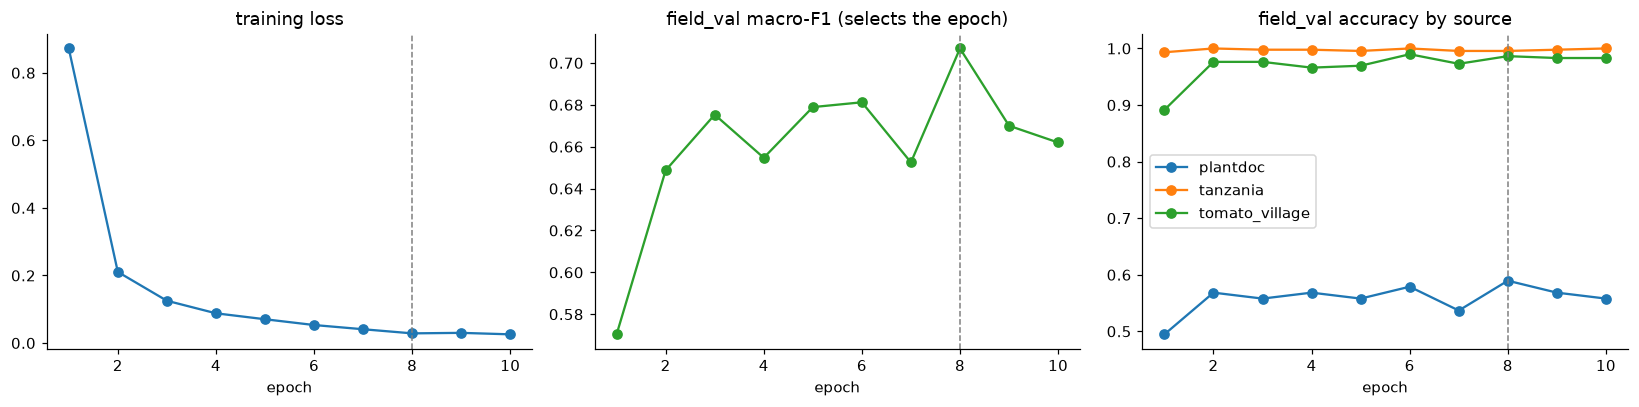

best epoch 8 (macro-F1 0.707); total training time 22 min


In [10]:
# The training run of the shipped model (v3), from its saved log
log = pd.DataFrame(json.loads((OUTPUTS / "final_v3_convnext_tiny_log.json").read_text())["epochs"])
src = pd.DataFrame(log["val_acc_by_source"].tolist())
best_epoch = int(log.loc[log["val_macro_f1"].idxmax(), "epoch"])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(log["epoch"], log["train_loss"], "o-"); ax[0].set_title("training loss")
ax[1].plot(log["epoch"], log["val_macro_f1"], "o-", color="C2"); ax[1].set_title("field_val macro-F1 (selects the epoch)")
for c in src: ax[2].plot(log["epoch"], src[c], "o-", label=c)
ax[2].set_title("field_val accuracy by source"); ax[2].legend()
for a in ax:
    a.axvline(best_epoch, color="grey", ls="--", lw=1); a.set_xlabel("epoch")
plt.tight_layout(); plt.show()
print(f"best epoch {best_epoch} (macro-F1 {log['val_macro_f1'].max():.3f}); "
      f"total training time {log['seconds'].sum()/60:.0f} min")

## 5. Evaluation on held-out photos

We load the shipped model (`final_v3_convnext_tiny.pt`, the best epoch above) and run it on:
* `lab_test`: lab photos it never trained on;
* `field_test`: **1,306 real field photos**, 476 from PlantDoc and 830 from Tanzania, never used for training or choices;
* `field_cal`: 545 field photos, used only to fit the calibration in sections 6–7.

In [11]:
ckpt = torch.load(OUTPUTS / "final_v3_convnext_tiny.pt", map_location=DEV)
model = build_model(len(ckpt["classes"]), pretrained=False, arch=ckpt["arch"])
model.load_state_dict(ckpt["state_dict"]); model = model.to(DEV).eval()
assert ckpt["classes"] == CLASSES
print("loaded epoch", ckpt.get("epoch"), "| field_val macro-F1", round(ckpt.get("val_macro_f1", float("nan")), 4))

def get_logits(split):
    df = S[split] if split in S else pd.read_csv(SPLITS / f"{split}.csv")
    if "label_idx" not in df:      # never-seen diseases have no class number: treat them as "something else" (tomato)
        df = df.assign(label_idx=CLASSES.index("tomato_something_else"))
    dl = DataLoader(FrameDataset(df, eval_transform()), batch_size=64, num_workers=WORKERS)
    y = df["label_idx"].to_numpy()
    return mask_logits(logits_of(model, dl, DEV), CLASSES, crops_from_labels(y, CLASSES)), y, df

t0 = time.time()
L = {s: get_logits(s) for s in ["lab_test", "field_test", "field_cal"]}
print(f"inference on {sum(len(v[1]) for v in L.values())} photos: {time.time()-t0:.0f} s")

loaded epoch 8 | field_val macro-F1 0.7069


inference on 3574 photos: 67 s


In [12]:
def scores(logits, y):
    pred = logits.argmax(1)
    return {"photos": len(y), "accuracy": (pred == y).mean(), "macro-F1": f1_score(y, pred, average="macro")}

lt, yt, dft = L["field_test"]
rows = {"lab_test (PlantVillage)": scores(*L["lab_test"][:2]), "field_test: all": scores(lt, yt)}
for s in ["plantdoc", "tanzania"]:
    m = (dft["source"] == s).to_numpy()
    rows[f"field_test: {s}"] = scores(lt[m], yt[m])
pd.DataFrame(rows).T.style.format({"accuracy": "{:.1%}", "macro-F1": "{:.3f}", "photos": "{:.0f}"})

,photos,accuracy,macro-F1
lab_test (PlantVillage),1723,99.7%,0.997
field_test: all,1306,86.4%,0.719
field_test: plantdoc,476,63.7%,0.638
field_test: tanzania,830,99.5%,0.995


**Reading these numbers honestly**
* Lab photos are nearly solved.
* The Tanzania test photos come from the same farms as its training photos, so its ~99% is *in-distribution* and optimistic.
* **PlantDoc (web photos from many places) is the hard, independent test.** About 64% is the realistic accuracy on unfamiliar field photos. For comparison, a model trained on lab photos alone got about 25% on these photos (Day 2).
* This gap is exactly why the model must know when it is unsure (sections 6–8).

In [13]:
pred_t = lt.argmax(1)
used = sorted(set(yt) | set(pred_t))
print(classification_report(yt, pred_t, labels=used, target_names=[CLASSES[i] for i in used], digits=3, zero_division=0))

                          precision    recall  f1-score   support

     potato_early_blight      0.944     0.931     0.937       305
          potato_healthy      1.000     1.000     1.000       296
      potato_late_blight      0.938     0.949     0.944       335
   tomato_bacterial_spot      0.338     0.400     0.367        55
     tomato_early_blight      0.528     0.636     0.577        44
          tomato_healthy      0.720     0.581     0.643        31
      tomato_late_blight      0.733     0.786     0.759        56
        tomato_leaf_mold      0.735     0.556     0.633        45
     tomato_mosaic_virus      0.609     0.519     0.560        27
         tomato_septoria      0.680     0.680     0.680        75
tomato_yellow_curl_virus      0.829     0.784     0.806        37

                accuracy                          0.864      1306
               macro avg      0.732     0.711     0.719      1306
            weighted avg      0.869     0.864     0.866      1306



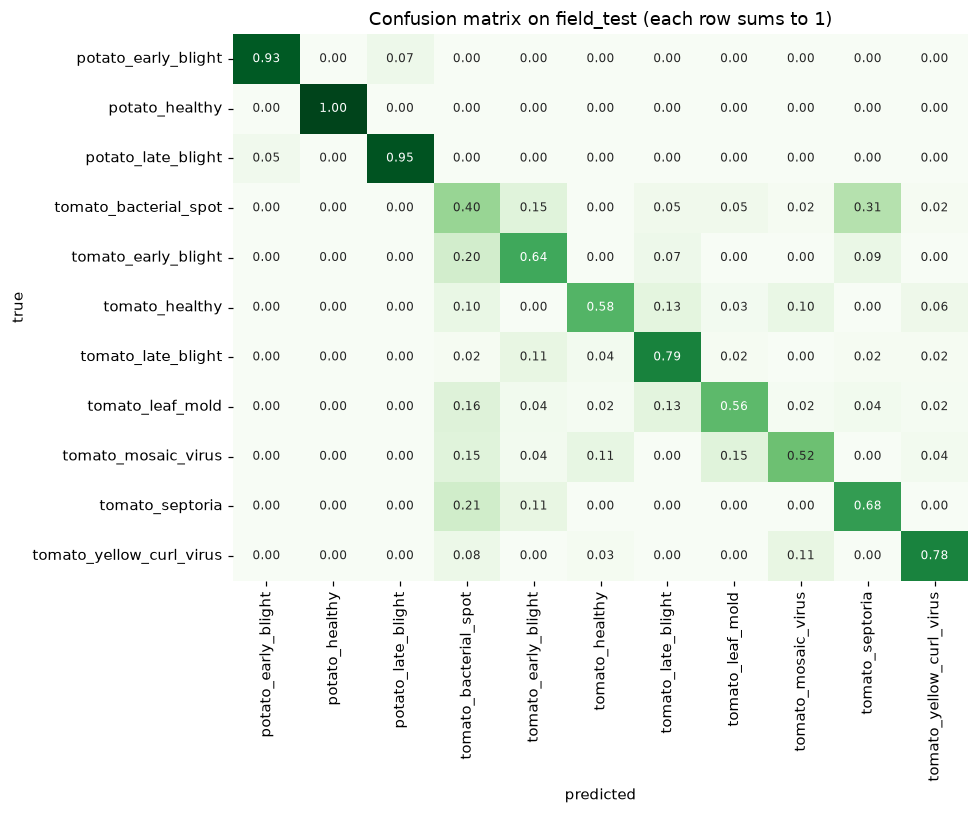

In [14]:
cm = confusion_matrix(yt, pred_t, labels=used, normalize="true")
plt.figure(figsize=(9, 7.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Greens", xticklabels=[CLASSES[i] for i in used],
            yticklabels=[CLASSES[i] for i in used], cbar=False, annot_kws={"size": 8})
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Confusion matrix on field_test (each row sums to 1)")
plt.tight_layout(); plt.show()

### Where does the model look? (Grad-CAM)

Grad-CAM (Selvaraju et al., 2017) colours the parts of the image that pushed the score of the predicted class up. It uses the gradients of that score with respect to the last convolutional stage. Good predictions should focus on the spots and lesions, not on the background.

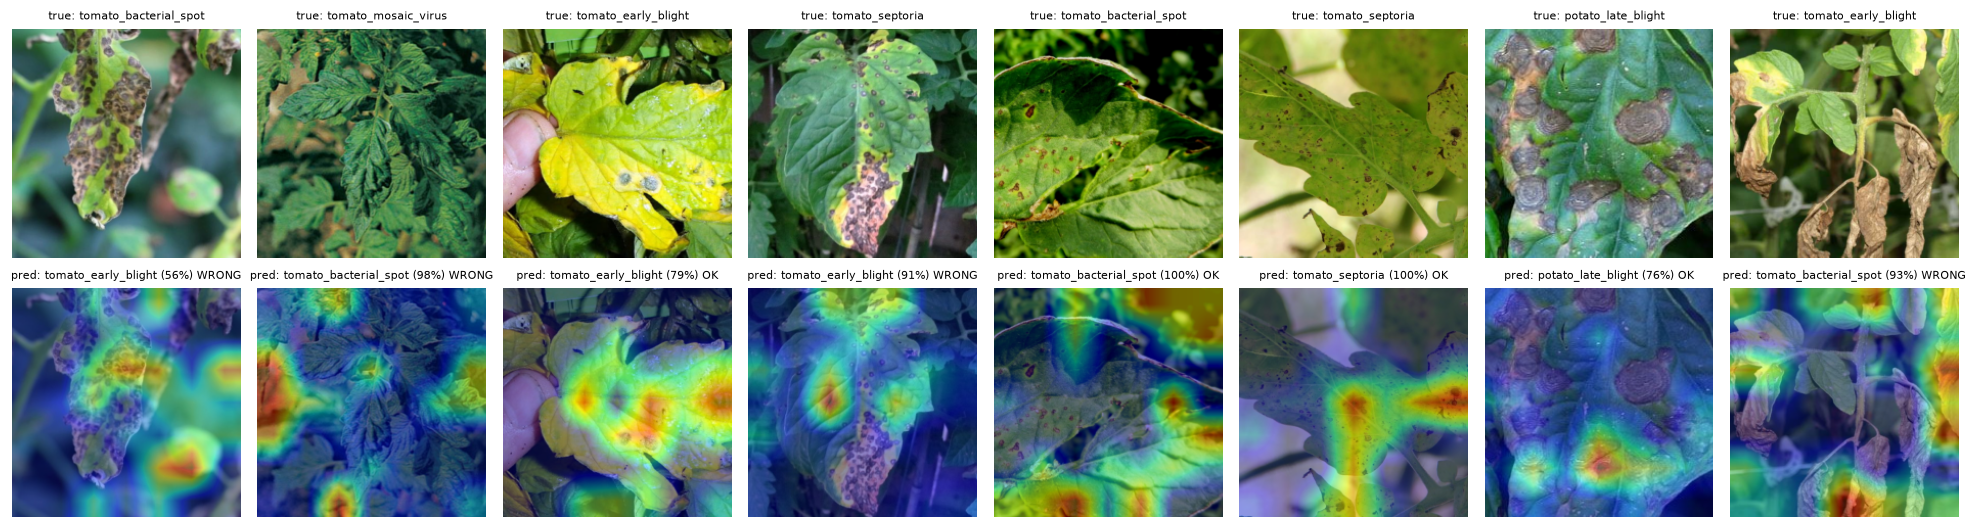

In [15]:
def grad_cam(net, x, cls):
    acts, grads = {}, {}
    layer = net.stages[-1]
    h1 = layer.register_forward_hook(lambda m, i, o: acts.update(a=o))
    h2 = layer.register_full_backward_hook(lambda m, gi, go: grads.update(g=go[0]))
    net.zero_grad(); out = net(x); out[0, cls].backward()
    h1.remove(); h2.remove()
    w = grads["g"].mean(dim=(2, 3), keepdim=True)                     # importance of each channel
    cam = torch.relu((w * acts["a"]).sum(1, keepdim=True))
    cam = torch.nn.functional.interpolate(cam, size=x.shape[-2:], mode="bilinear")[0, 0]
    return (cam / (cam.max() + 1e-8)).detach().cpu().numpy()

pd_test = dft[dft["source"] == "plantdoc"].sample(8, random_state=11)
probs_t = softmax(lt, 1.0)
fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for j, (i, row) in enumerate(pd_test.iterrows()):
    with Image.open(config.DATASETS_DIR / row["path"]) as im:
        x = eval_transform()(im.convert("RGB"))[None].to(DEV)
    k = int(lt[i].argmax()); cam = grad_cam(model, x, k)
    ok = "OK" if k == row["label_idx"] else "WRONG"
    axes[0, j].imshow(to_img(x[0].cpu())); axes[0, j].set_title(f"true: {row['label']}", fontsize=7)
    axes[1, j].imshow(to_img(x[0].cpu())); axes[1, j].imshow(cam, cmap="jet", alpha=0.45)
    axes[1, j].set_title(f"pred: {CLASSES[k]} ({probs_t[i, k]:.0%}) {ok}", fontsize=7)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

Read the maps honestly. On several photos the model looks at the spots, but on some, including wrong answers, it looks at background or other leaves. That is one reason accuracy on busy web photos is far below accuracy on lab photos, and why the app asks or defers when it is unsure.

## 6. Calibration: is the confidence honest?

A model is *calibrated* if, among the photos where it says "80% sure", about 80% are right.

Deep networks are usually **over-confident**. **Temperature scaling** (Guo et al., 2017) divides every logit by one number T, chosen to minimise the negative log-likelihood on the calibration photos (`field_cal`). It never changes *which* class is predicted, only *how sure* the model says it is.

**ECE** (expected calibration error) is the average gap between confidence and accuracy. Lower is better; 0 is perfect.

In [16]:
lc, yc, dfc = L["field_cal"]
T = fit_temperature(lc, yc)
p_raw, p_cal = softmax(lt, 1.0), softmax(lt, T)
print(f"fitted temperature T = {T:.3f}  (T > 1: the raw model was over-confident)")
pd.DataFrame({"before (T=1)": {"accuracy": (p_raw.argmax(1) == yt).mean(), "ECE": ece(p_raw, yt), "NLL": nll(p_raw, yt)},
              f"after (T={T:.2f})": {"accuracy": (p_cal.argmax(1) == yt).mean(), "ECE": ece(p_cal, yt), "NLL": nll(p_cal, yt)}}
             ).style.format("{:.4f}")

fitted temperature T = 1.652  (T > 1: the raw model was over-confident)


,before (T=1),after (T=1.65)
accuracy,0.8645,0.8645
ECE,0.0787,0.0288
NLL,0.5037,0.4110


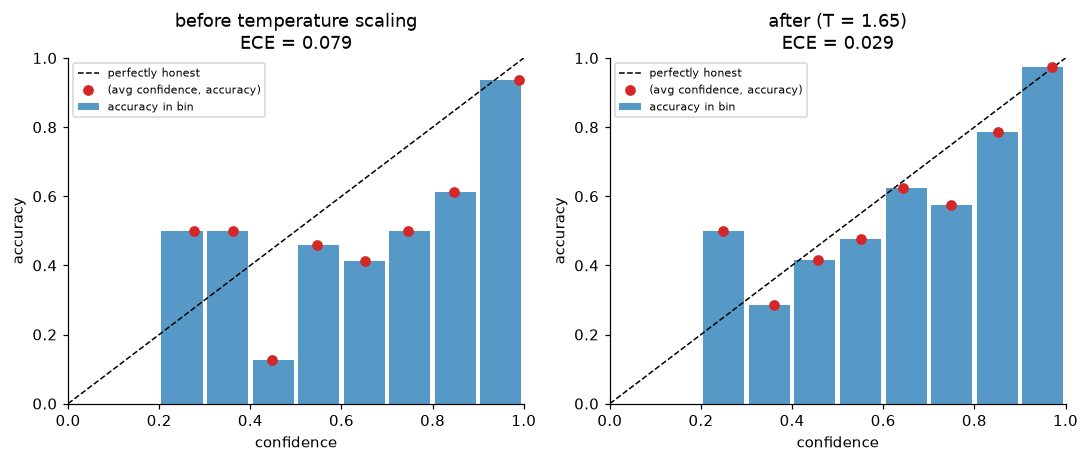

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
for a, (p, title) in zip(axes, [(p_raw, "before temperature scaling"), (p_cal, f"after (T = {T:.2f})")]):
    b = reliability_bins(p, yt, n_bins=10); m = b["count"] > 0
    centers = (b["edges"][:-1] + b["edges"][1:]) / 2
    a.bar(centers[m], b["accuracy"][m], width=0.09, alpha=0.75, label="accuracy in bin")
    a.plot([0, 1], [0, 1], "k--", lw=1, label="perfectly honest")
    a.plot(b["confidence"][m], b["accuracy"][m], "o", color="C3", label="(avg confidence, accuracy)")
    a.set(xlim=(0, 1), ylim=(0, 1), xlabel="confidence", ylabel="accuracy", title=f"{title}\nECE = {ece(p, yt):.3f}")
    a.legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.show()

## 7. Conformal prediction: a shortlist with a 90% guarantee

Instead of one answer, the model gives a **shortlist** of diseases. Split conformal prediction (APS score, Romano et al., 2020) picks a threshold q̂ on the calibration photos so that:

$$P(\text{true disease} \in \text{shortlist}) \ge 1-\alpha = 90\%$$

for any new photo that is exchangeable with the calibration photos. The only assumption is exchangeability; no assumption about the model is needed.

* **Per crop (Mondrian):** a separate q̂ for tomato and for potato, so *each crop* gets its own 90% promise.
* **Randomised APS:** coverage is exactly 90%, not much more. A side effect is that a shortlist can be empty, which the app treats as "send to an expert".
* **q̂** is the ⌈(n+1)(1−α)⌉-th smallest calibration score. The "+1" is the finite-sample correction.

**App rule:** 1 disease → answer; 2–3 diseases → ask one follow-up question; empty or more than 3 → send to an expert.

In [18]:
ALPHA = 0.1
cal_crops, test_crops = crops_from_labels(yc, CLASSES), crops_from_labels(yt, CLASSES)
p_cal_cal = softmax(lc, T)
qhat = group_quantiles(p_cal_cal, yc, cal_crops, ALPHA, uniform_noise(len(yc), 7))
sets = group_prediction_sets(p_cal, qhat, test_crops, uniform_noise(len(yt), 12345))
print("q-hat per crop:", {k: round(v, 4) for k, v in qhat.items()},
      "| calibration photos per crop:", pd.Series(cal_crops).value_counts().to_dict())

covered = sets[np.arange(len(yt)), yt]; size = sets.sum(1)
groups = {"all": np.ones(len(yt), bool), "tomato": test_crops == "tomato", "potato": test_crops == "potato",
          "PlantDoc": (dft["source"] == "plantdoc").to_numpy(), "Tanzania": (dft["source"] == "tanzania").to_numpy()}
pd.DataFrame({g: {"photos": m.sum(), "coverage (target 90%)": covered[m].mean(), "avg shortlist size": size[m].mean()}
              for g, m in groups.items()}).T.style.format({"photos": "{:.0f}", "coverage (target 90%)": "{:.1%}",
                                                           "avg shortlist size": "{:.2f}"})

q-hat per crop: {'potato': 0.8771, 'tomato': 0.9515} | calibration photos per crop: {'potato': 471, 'tomato': 74}


,photos,coverage (target 90%),avg shortlist size
all,1306,90.5%,1.66
tomato,370,92.4%,3.38
potato,936,89.7%,0.98
PlantDoc,476,89.7%,2.94
Tanzania,830,91.0%,0.93


,share of photos,accuracy of the top answer
answer alone (1 disease),67.4%,96.4%
ask one question (2-3),14.5%,65.3%
send to expert (0 or >3),18.1%,66.5%


Plain model: 86.4% right on every photo.  Crop Doctor: answers 67% of photos alone and is right 96.4% of those times.


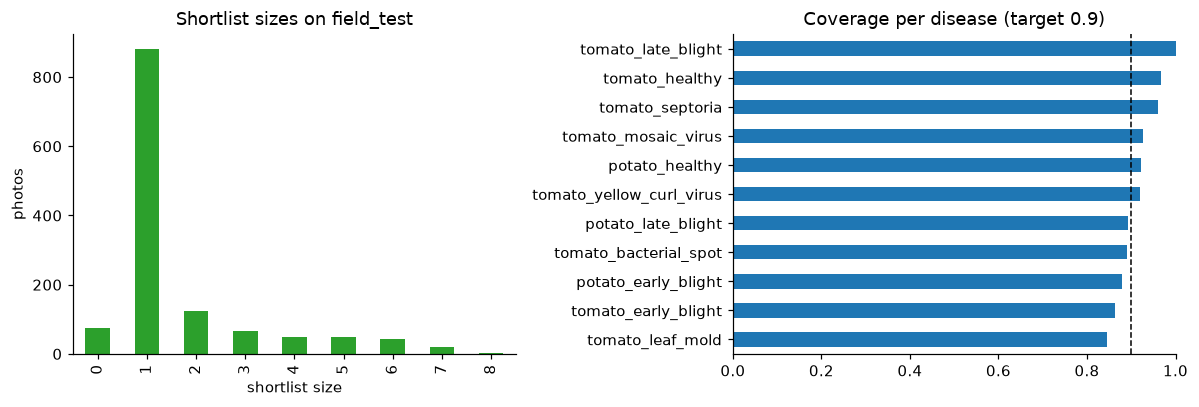

In [19]:
# What the app does with each test photo
answer = size == 1; ask = (size >= 2) & (size <= 3); expert = (size == 0) | (size > 3)
top_ok = p_cal.argmax(1) == yt
decision = pd.DataFrame({
    "share of photos": [answer.mean(), ask.mean(), expert.mean()],
    "accuracy of the top answer": [top_ok[answer].mean(), top_ok[ask].mean(), top_ok[expert].mean()],
}, index=["answer alone (1 disease)", "ask one question (2-3)", "send to expert (0 or >3)"])
display(decision.style.format("{:.1%}"))
print(f"Plain model: {top_ok.mean():.1%} right on every photo.  "
      f"Crop Doctor: answers {answer.mean():.0%} of photos alone and is right {top_ok[answer].mean():.1%} of those times.")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
pd.Series(size).value_counts().sort_index().plot.bar(ax=ax[0], color="C2")
ax[0].set(xlabel="shortlist size", ylabel="photos", title="Shortlist sizes on field_test")
cc = class_coverage(sets, yt, len(CLASSES))
pd.Series(cc, index=CLASSES).dropna().sort_values().plot.barh(ax=ax[1], color="C0")
ax[1].axvline(0.9, color="k", ls="--", lw=1); ax[1].set(xlim=(0, 1), title="Coverage per disease (target 0.9)")
plt.tight_layout(); plt.show()

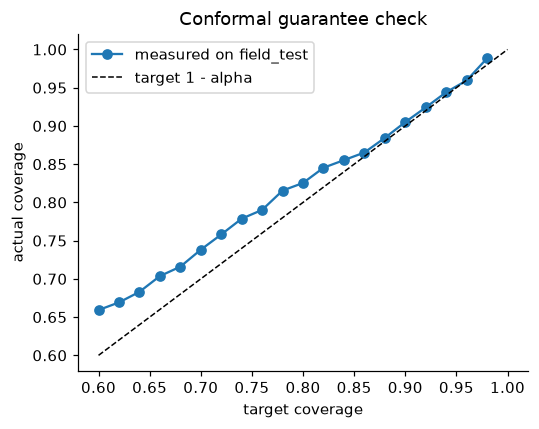

In [20]:
# Does the guarantee hold for any alpha? Coverage should follow the 1 - alpha line.
alphas = np.linspace(0.02, 0.4, 20); cov = []
for a in alphas:
    q = group_quantiles(p_cal_cal, yc, cal_crops, a, uniform_noise(len(yc), 7))
    s = group_prediction_sets(p_cal, q, test_crops, uniform_noise(len(yt), 12345))
    cov.append(s[np.arange(len(yt)), yt].mean())
plt.figure(figsize=(5, 4))
plt.plot(1 - alphas, cov, "o-", label="measured on field_test"); plt.plot([0.6, 1], [0.6, 1], "k--", lw=1, label="target 1 - alpha")
plt.xlabel("target coverage"); plt.ylabel("actual coverage"); plt.legend(); plt.title("Conformal guarantee check")
plt.tight_layout(); plt.show()

**Note on potato.** The potato top answer is right about 99% of the time on Tanzania, yet the shortlist covers only about 91%. Randomised APS deliberately empties a few confident shortlists so that coverage lands at 90% rather than far above it. In the app those photos go to an expert: the system is slightly more cautious than it needs to be on easy photos.

## 8. Selective prediction: answer only when sure

Sort the photos by confidence and answer only the most confident ones. The **risk–coverage curve** shows the error rate among the answered photos as more photos are answered.

**AURC** is the area under that curve; lower is better. The *oracle* line ranks every correct answer before every mistake, which is the best any confidence score could do.

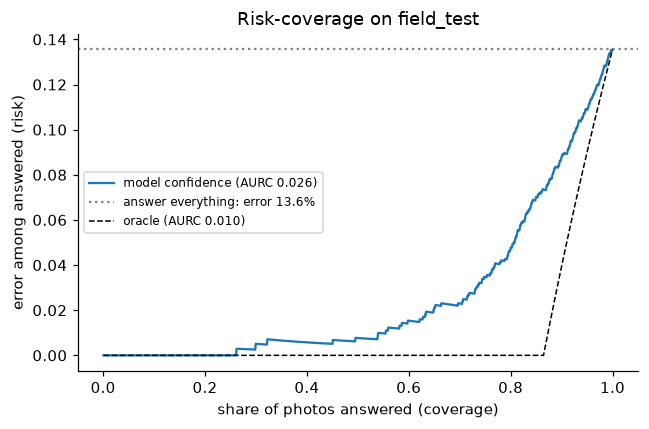

answer the 50% most confident photos -> accuracy 99.2%
answer the 70% most confident photos -> accuracy 97.7%
answer the 90% most confident photos -> accuracy 91.2%


In [21]:
conf = p_cal.max(1)
cov_c, risk = risk_coverage(conf, top_ok)
plt.figure(figsize=(6, 4))
plt.plot(cov_c, risk, label=f"model confidence (AURC {aurc(conf, top_ok):.3f})")
plt.axhline(1 - top_ok.mean(), color="grey", ls=":", label=f"answer everything: error {1-top_ok.mean():.1%}")
cov_o, risk_o = risk_coverage(top_ok.astype(float) + 1e-9 * np.random.rand(len(top_ok)), top_ok)
plt.plot(cov_o, risk_o, "k--", lw=1, label=f"oracle (AURC {oracle_aurc(top_ok):.3f})")
plt.xlabel("share of photos answered (coverage)"); plt.ylabel("error among answered (risk)")
plt.legend(fontsize=8); plt.title("Risk-coverage on field_test"); plt.tight_layout(); plt.show()
for c in [0.5, 0.7, 0.9]:
    k = int(c * len(conf)); idx = np.argsort(-conf)[:k]
    print(f"answer the {c:.0%} most confident photos -> accuracy {top_ok[idx].mean():.1%}")

## 9. Unknown diseases: the "something else" class

A classifier must name one of its classes even for a disease it never learned. Following *outlier exposure* (Hendrycks et al., 2019), v3 has a 12th class, **"tomato_something_else"**. It was trained on two *other* tomato problems: leaf miner and magnesium deficiency.

The test uses three problems it has **never seen**: spotted wilt virus, nitrogen deficiency and potassium deficiency (`unknown_heldout`). A good system should *not* confidently name a known disease for these photos.

In [22]:
lu, yu, dfu = get_logits("unknown_heldout")
pu = softmax(lu, T)
su = group_prediction_sets(pu, qhat, np.array(["tomato"] * len(pu)), uniform_noise(len(pu), 12345))
OTHER = CLASSES.index("tomato_something_else")
top_other = pu.argmax(1) == OTHER
named_one = (su.sum(1) == 1) & ~su[:, OTHER] & ~top_other
print(f"{len(pu)} photos of never-seen tomato problems ({dfu['disease'].value_counts().to_dict()})")
print(f"  flagged 'something else' (top answer)            : {top_other.mean():.1%}")
print(f"  confidently named ONE known disease (bad outcome) : {named_one.mean():.1%}")
print(f"  shortlist / question / expert instead             : {1 - named_one.mean() - top_other.mean():.1%}")

948 photos of never-seen tomato problems ({'Spotted Wilt Virus': 517, 'Nitrogen Deficiency': 359, 'Pottassium Deficiency': 72})
  flagged 'something else' (top answer)            : 54.3%
  confidently named ONE known disease (bad outcome) : 18.7%
  shortlist / question / expert instead             : 27.0%


The 11-class v2 model, with no "something else" class, confidently named a known disease for about 43% of these photos (Exp 8/10). The extra class reduces that a lot.

**Caveat:** every "something else" photo, in training and in this test, is a Tomato-Village leaf photographed on paper. The class may partly have learned "a photo on paper". It has not been tested on unknown diseases photographed in a real field.

## 10. Summary

In [23]:
summary = pd.Series({
    "Lab test accuracy": f"{scores(*L['lab_test'][:2])['accuracy']:.1%}",
    "Field test accuracy (1,306 photos)": f"{top_ok.mean():.1%}",
    "  PlantDoc (independent web photos)": f"{rows['field_test: plantdoc']['accuracy']:.1%}",
    "  Tanzania (in-distribution farms)": f"{rows['field_test: tanzania']['accuracy']:.1%}",
    "Field test macro-F1": f"{rows['field_test: all']['macro-F1']:.3f}",
    "ECE before -> after temperature scaling": f"{ece(p_raw, yt):.3f} -> {ece(p_cal, yt):.3f}",
    "Shortlist coverage (target 90%)": f"{covered.mean():.1%}",
    "Photos answered alone": f"{answer.mean():.1%}",
    "Accuracy when answering alone": f"{top_ok[answer].mean():.1%}",
    "Unknown diseases confidently misnamed": f"{named_one.mean():.1%}",
}, name="ConvNeXt-Tiny v3")
summary.to_frame()

,ConvNeXt-Tiny v3
Lab test accuracy,99.7%
"Field test accuracy (1,306 photos)",86.4%
PlantDoc (independent web photos),63.7%
Tanzania (in-distribution farms),99.5%
Field test macro-F1,0.719
ECE before -> after temperature scaling,0.079 -> 0.029
Shortlist coverage (target 90%),90.5%
Photos answered alone,67.4%
Accuracy when answering alone,96.4%
Unknown diseases confidently misnamed,18.7%


**Main points**
1. **Transfer learning plus field data:** ImageNet-22k ConvNeXt-Tiny, trained on mixed lab and field batches with square-root class balancing, and chosen by field-validation macro-F1.
2. **Honest about accuracy:** about 64% on independent PlantDoc web photos is the real difficulty. Lab accuracy says little about the field.
3. **Honest about uncertainty:** temperature scaling fixes over-confidence. Per-crop conformal prediction gives a shortlist that meets its 90% promise on the test photos. Using the shortlist, the app answers alone only when it is very likely right and asks or defers otherwise.

**Limitations**
* Tanzania test photos come from the same farms as its training photos, so its ~99% is optimistic.
* PlantDoc labels are noisy. A perceptual-hash audit found 24 PlantDoc test photos with resized copies in the training splits. Removing them changes accuracy by less than half a point (`crop_doctor/outputs/metrics/near_duplicates.json`).
* The 90% guarantee is *on average* over photos like the calibration photos. Some individual diseases are below 90%, and photos from a new place need new calibration labels. The app collects these through random expert audits.
* One training run (seed 42), so there are no error bars over training seeds.